# Preparación del entorno
El primer paso será importar todas las librerias necesarias.

In [3]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\XxDEs\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\XxDEs\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\XxDEs\AppData\Roaming\nltk_data...


True

# Carga, limpieza y preprocesamiento de los datos
Cargamos los datos, nos quedamos solo con las columnas que son relevantes y preprocesamos los datos. 

In [6]:
ruta_archivo = './spam.csv'
df = pd.read_csv(ruta_archivo, encoding='latin-1')

df = df.iloc[:, :2]

df.columns = ['label', 'message']

stop_words = set(stopwords.words('english')) # El dataset está en inglés
lemmatizer = WordNetLemmatizer()

def preprocesar_texto(texto):
    texto = texto.lower()
    
    texto = re.sub(r'[^a-z\s]', '', texto)

    tokens = word_tokenize(texto)
    
    tokens_procesados = [lemmatizer.lemmatize(word) for word in tokens if word not in stop_words]
    
    return ' '.join(tokens_procesados)

df['clean_message'] = df['message'].apply(preprocesar_texto)

df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

df.head()

,label,message,clean_message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...,0
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...,1
3,ham,U dun say so early hor... U c already then say...,u dun say early hor u c already say,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though,0


# Representación de los mensajes y división del conjunto de datos
Para optimizar el rendimiento limitamos las características a 5000. Luego, dividiremos el conjunto en dos, uno para el entrenamiento y otro para validación. 

In [7]:
vectorizer = TfidfVectorizer(max_features=5000)
X = vectorizer.fit_transform(df['clean_message'])

y = df['label_num']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Tamaño del set de entrenamiento: {X_train.shape[0]} muestras")
print(f"Tamaño del set de validación: {X_test.shape[0]} muestras")

Tamaño del set de entrenamiento: 4457 muestras
Tamaño del set de validación: 1115 muestras


# Modelo de clasificación
Vamos a seleccionar el modelo Naive Bayes. 

In [8]:
modelo_nb = MultinomialNB()

modelo_nb.fit(X_train, y_train)

y_pred = modelo_nb.predict(X_test)

print("Entrenamiento del modelo completado.")

Entrenamiento del modelo completado.


# Evaluación de resultados
Después del entrenamiento vamos a evaluar el rendimiento del modelo. Para ello usaremos diferentes métricas. 

=== Reporte de Métricas del Modelo ===
Precisión (Accuracy): 0.9668
Recall: 0.7584
F1-Score: 0.8593


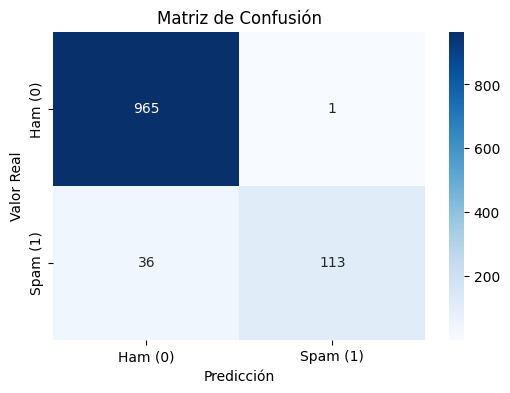

In [9]:
precision = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
matriz_conf = confusion_matrix(y_test, y_pred)

print("=== Reporte de Métricas del Modelo ===")
print(f"Precisión (Accuracy): {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

plt.figure(figsize=(6, 4))
sns.heatmap(matriz_conf, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Ham (0)', 'Spam (1)'], 
            yticklabels=['Ham (0)', 'Spam (1)'])
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Valor Real')
plt.show()